# Optimization for data science: Project 2025-2026
## Frank-Wolfe methods for LASSO optimisation

Tamari Matikashvili 2121549

Alessandro Di Frenna 2160704



# Imports

In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from ucimlrepo import fetch_ucirepo
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix


# Algorithms

##Frank-Wolfe Classic Lasso

In [ ]:
def frank_wolfe_lasso(X, y, t, max_iter=1000, tol=1e-8):
    m, n = X.shape

    # Start from a feasible point: ||beta||_1 = 0 <= t
    beta = np.zeros(n)

    # residual = X beta - y
    residual = -y.copy()
    obj_history = [0.5 * (residual @ residual) / m]
    gap_history = []

    for k in range(max_iter):
        # Gradient
        grad = X.T @ residual / m

        # Lmo
        i_star = np.argmax(np.abs(grad))

        s = np.zeros(n)
        s[i_star] = -t * np.sign(grad[i_star])

        # direction
        d = s - beta

        # duality gap
        gap = -grad @ d
        gap_history.append(gap)

        if gap <= tol:
            break

        # exact line search
        Xd = X @ d

        denominator = Xd @ Xd

        if denominator <= 1e-15:
            alpha = 0.0

        else:
            alpha = -(residual @ Xd) / denominator
            alpha = np.clip(alpha, 0.0, 1.0)

        # update
        beta = beta + alpha * d

        # residual update
        residual = residual + alpha * Xd

        # objective value record
        obj = 0.5 * (residual @ residual) / m
        obj_history.append(obj)

    history = {
        "objective": obj_history,
        "duality_gap": gap_history
    }

    return beta, history

## Away-Step Frank-Wolfe

In [ ]:
def away_step_frank_wolfe_lasso(X, y, t, max_iter=1000, tol=1e-8):

    m, n = X.shape

    def make_atom(key):
        i, sign = key
        atom = np.zeros(n)
        atom[i] = sign * t
        return atom

    # starting atom
    residual_zero = -y.copy()
    grad_zero = X.T @ residual_zero / m

    i_start = np.argmax(np.abs(grad_zero))

    beta = np.zeros(n)
    beta[i_start] = -t * np.sign(grad_zero[i_start])

    start_key = (i_start, int(np.sign(beta[i_start])))

    # active atoms and their weights
    weights = {start_key: 1.0}

    residual = X @ beta - y

    obj_history = []
    gap_history = []
    active_size_history = []

    for k in range(max_iter):

        # gradient
        grad = X.T @ residual / m

        # fw atom
        i_fw = np.argmax(np.abs(grad))

        s = np.zeros(n)
        s[i_fw] = -t * np.sign(grad[i_fw])

        fw_key = (i_fw, int(np.sign(s[i_fw])))

        # direction and gap
        d_fw = s - beta
        gap_fw = -grad @ d_fw

        gap_history.append(gap_fw)

        if gap_fw <= tol:
            break

        # away atom: worst atom in current active set
        away_key = None
        best_score = -np.inf

        for key in weights:
            i, sign = key
            score = sign * t * grad[i]

            if score > best_score:
                best_score = score
                away_key = key

        v = make_atom(away_key)

        # away direction
        d_away = beta - v
        gap_away = -grad @ d_away

        # choose fw or away direction
        if gap_fw >= gap_away:

            d = d_fw
            gamma_max = 1.0
            step_type = "FW"

        else:

            d = d_away
            alpha_v = weights[away_key]

            if alpha_v >= 1.0:
                gamma_max = 0.0
            else:
                gamma_max = alpha_v / (1.0 - alpha_v)

            step_type = "away"

        # exact line search
        Xd = X @ d
        denominator = Xd @ Xd

        if denominator <= 1e-15:
            gamma = 0.0
        else:
            gamma_star = -(residual @ Xd) / denominator
            gamma = np.clip(gamma_star, 0.0, gamma_max)

        # update
        beta = beta + gamma * d
        residual = residual + gamma * Xd

        # update active weights
        if step_type == "FW":

            for key in list(weights.keys()):
                weights[key] *= (1.0 - gamma)

            weights[fw_key] = weights.get(fw_key, 0.0) + gamma

        else:

            for key in list(weights.keys()):
                weights[key] *= (1.0 + gamma)

            weights[away_key] -= gamma

        # remove zero-weight atoms
        remove_keys = []

        for key, weight in weights.items():
            if weight <= 1e-12:
                remove_keys.append(key)

        for key in remove_keys:
            del weights[key]

        # objective
        obj = 0.5 * (residual @ residual) / m

        obj_history.append(obj)
        active_size_history.append(len(weights))

    history = {
        "objective": obj_history,
        "duality_gap": gap_history,
        "active_size": active_size_history
    }

    return beta, history

## Pairwise Frank-Wolfe

In [ ]:
def frank_wolfe_pairwise(X, y, t, max_iter=1000, tol=1e-8):

    m, n = X.shape

    def make_atom(key):
        i, sign = key
        atom = np.zeros(n)
        atom[i] = sign * t
        return atom

    # choose starting atom : we use lmo at beta = 0
    beta_zero = np.zeros(n)
    residual_zero = -y.copy()
    grad_zero = X.T @ residual_zero / m

    i_start = np.argmax(np.abs(grad_zero))

    beta = np.zeros(n)
    beta[i_start] = -t * np.sign(grad_zero[i_start])

    start_key = (i_start, int(np.sign(beta[i_start])))

    # active atoms and weights
    weights = {start_key: 1.0}
    residual = X @ beta - y

    obj_history = []
    gap_history = []
    active_size_history = []

    for k in range(max_iter):

        # gradient
        grad = X.T @ residual / m

        # atom
        i_fw = np.argmax(np.abs(grad))

        s = np.zeros(n)
        s[i_fw] = -t * np.sign(grad[i_fw])

        fw_key = (i_fw, int(np.sign(s[i_fw])))

        # duality gap
        d_fw = s - beta
        gap = -grad @ d_fw

        gap_history.append(gap)

        if gap <= tol:
            break

        # away atom
        away_key = None
        best_score = -np.inf

        for key in weights:
            i, sign = key
            score = sign * t * grad[i]

            if score > best_score:
                best_score = score
                away_key = key

        v = make_atom(away_key)   #only the winning atom

        #direction
        d = s - v

        # maximum feasible step
        gamma_max = weights[away_key]

        # exact line search
        Xd = X @ d
        denominator = Xd @ Xd

        if denominator <= 1e-15:
            gamma = 0.0

        else:
            gamma_star = -(residual @ Xd) / denominator
            gamma = np.clip(gamma_star, 0.0, gamma_max)

        # update
        beta = beta + gamma * d
        residual = residual + gamma * Xd

        # transfer weight from away atom to FW atom
        weights[away_key] -= gamma
        weights[fw_key] = weights.get(fw_key, 0.0) + gamma

        # remove zero weights
        remove_keys = []

        for key, weight in weights.items():
            if weight <= 1e-12:
                remove_keys.append(key)

        for key in remove_keys:
            del weights[key]

        obj = 0.5 * (residual @ residual) / m

        obj_history.append(obj)
        active_size_history.append(len(weights))

    history = {
        "objective": obj_history,
        "duality_gap": gap_history,
        "active_size": active_size_history
    }

    return beta, history

# Evals and plotting functions

In [ ]:
def evaluate(method_fn, max_iter, X_train, y_train_c, X_test, y_test, y_mean, t=0.5, tol=1e-8):
    n_test = X_test.shape[0]

    start = time.perf_counter()
    beta, history = method_fn(X_train, y_train_c, t, max_iter=max_iter, tol=tol)
    elapsed = time.perf_counter() - start

    niter = len(history["duality_gap"])

    y_pred = X_test @ beta + y_mean   # uncenter

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    p = np.count_nonzero(np.abs(beta) > 1e-10)
    if n_test > p + 1:
        adj_r2 = 1 - ((1 - r2) * (n_test - 1)) / (n_test - p - 1)
    else:
        adj_r2 = np.nan

    return {
        "time_s": elapsed, "mse": mse, "r2": r2, "adj_r2": adj_r2,
        "nnz": p, "history": history, "beta": beta, "n_iter": niter
    }

In [ ]:
def plot_gap_comparison(results, tol=1e-8):
    colors = {
        "Classic FW": "#a31d1d",     # deep red
        "Away-step FW": "#c98500",   # muted gold
        "Pairwise FW": "#1e375f",    # deep navy
    }

    plt.figure(figsize=(7.5, 4.8))
    for name, res in results.items():
        plt.semilogy(
            res["history"]["duality_gap"],
            label=name,
            linewidth=2,
            color=colors.get(name, "gray"),
        )
    plt.axhline(tol, linestyle="--", color="#888888", linewidth=1.3, label="tol")

    plt.xlabel("Iteration")
    plt.ylabel("Duality gap")
    plt.title("Convergence comparison", fontsize=13, fontweight="medium")
    plt.legend(frameon=False)
    plt.grid(True, alpha=0.3, linewidth=0.6)
    plt.gca().spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_fw_convergence(history, method_name, color="#a31d1d", tol=1e-8):
    obj_vals = history["objective"]
    gaps = history["duality_gap"]

    if len(obj_vals) == 0 or len(gaps) == 0:
        print("History is empty.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # Duality gap
    axes[0].semilogy(gaps, linewidth=2, color=color,
                      label=f"{method_name} (Final: {gaps[-1]:.2e})")
    axes[0].axhline(tol, linestyle="--", color="#888888", linewidth=1.2,
                     label=f"Threshold ({tol:.0e})")
    axes[0].set_title("Duality gap")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Gap (log scale)")
    axes[0].legend(frameon=False, fontsize=9)
    axes[0].grid(True, alpha=0.3, linewidth=0.6)
    axes[0].spines[["top", "right"]].set_visible(False)

    # Objective value
    axes[1].plot(obj_vals, linewidth=2, color=color,
                 label=f"{method_name} (Final: {obj_vals[-1]:.2f})")
    axes[1].set_title("Objective value")
    axes[1].set_xlabel("Iteration")
    axes[1].set_ylabel("Objective")
    axes[1].legend(frameon=False, fontsize=9)
    axes[1].grid(True, alpha=0.3, linewidth=0.6)
    axes[1].spines[["top", "right"]].set_visible(False)

    fig.suptitle(f"Frank-Wolfe convergence: {method_name}", fontsize=13, fontweight="medium")
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_sparsity_comparison(results, n_features, title="Sparsity comparison"):
    colors = {
        "Classic FW": "#a31d1d",
        "Away-step FW": "#c98500",
        "Pairwise FW": "#1e375f",
    }

    names = list(results.keys())
    nnz_vals = [results[n]["nnz"] for n in names]
    pct_vals = [100 * nnz / n_features for nnz in nnz_vals]

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    bars = ax.bar(names, pct_vals, color=[colors.get(n, "gray") for n in names], width=0.55)

    ax.set_ylim(0, max(pct_vals) * 1.15)

    for bar, nnz in zip(bars, nnz_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(pct_vals) * 0.02,
                f"{nnz}", ha="center", fontsize=10)

    ax.set_ylabel("% of features kept (non-zero)")
    ax.set_title(title, fontsize=13, fontweight="medium")
    ax.grid(True, axis="y", alpha=0.3, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [ ]:
def search_t(X_train, y_train_c, X_val, y_val, y_mean,
             t_range=(0.1, 2.0), n_candidates=40,
             max_iter=1000, tol=1e-4,
             title="Validation MSE vs t"):

    ols = LinearRegression(fit_intercept=False).fit(X_train, y_train_c)
    t_max = np.linalg.norm(ols.coef_, 1)
    print("t_max:", t_max)

    ts = np.linspace(t_range[0], t_range[1], n_candidates) * t_max
    results = []

    for t_cand in ts:
        beta, hist = frank_wolfe_pairwise(X_train, y_train_c, t=t_cand, max_iter=max_iter, tol=tol)
        y_pred_val = X_val @ beta + y_mean
        mse_val = mean_squared_error(y_val, y_pred_val)
        results.append((t_cand, mse_val, len(hist["duality_gap"])))

    results_arr = np.array(results, dtype=[('t', float), ('mse', float), ('n_iter', int)])
    best = results_arr[np.argmin(results_arr['mse'])]
    t_best = best["t"]

    plt.plot(results_arr["t"], results_arr["mse"], "-o", markersize=3, color="#1e375f")
    plt.axvline(t_best, color="#a31d1d", linestyle="--")
    plt.xlabel("t")
    plt.ylabel("Validation MSE")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

    print("Best t =", t_best)
    print("Best validation MSE =", best["mse"])
    print("Candidates hitting max_iter cap:", (results_arr["n_iter"] >= max_iter).sum())

    return t_best, results_arr

# Dataset 1: Concrete Compressive Strength dataset (UCI)

In [ ]:
!pip install ucimlrepo -q

In [ ]:
concrete = fetch_ucirepo(id=165)
X = concrete.data.features.values
y = concrete.data.targets.values.ravel()

print(X.shape, y.shape)

(1030, 8) (1030,)


In [ ]:
# missing values
print("NaNs in X:", np.isnan(X).sum())
print("NaNs in y:", np.isnan(y).sum())

#duplicate rows
df_check = pd.DataFrame(X)
df_check["y"] = y
n_dupes = df_check.duplicated().sum()
print("Duplicate rows:", n_dupes)

# all numeric
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)


NaNs in X: 0
NaNs in y: 0
Duplicate rows: 25
X dtype: float64
y dtype: float64


In [ ]:
# remove duplicates
df_full = pd.DataFrame(X)
df_full["y"] = y
df_full = df_full.drop_duplicates()

X = df_full.drop(columns="y").values
y = df_full["y"].values

print(X.shape, y.shape)

(1005, 8) (1005,)


In [ ]:
# train/test/val
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

# standartize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# center target
y_mean = y_train.mean()
y_train_c = y_train - y_mean

##choosing t

t_max: 43.07330392920453


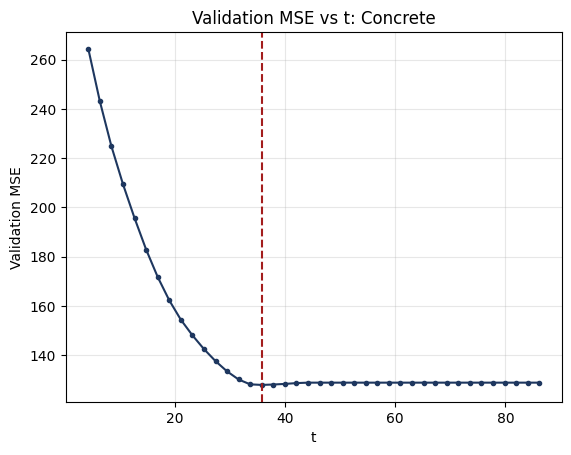

Best t = 35.78397557195453
Best validation MSE = 127.94873169960985
Candidates hitting max_iter cap: 6


In [ ]:
t_best, results_arr = search_t(X_train, y_train_c, X_val, y_val, y_mean,
                                title="Validation MSE vs t: Concrete")

##experiments

In [ ]:
# final eval on test, using t_best
max_iter = 5000

res_classic = evaluate(
    frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_away = evaluate(
    away_step_frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_pairwise = evaluate(
    frank_wolfe_pairwise, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

print(f"{'Method':<15} {'MSE':>10} {'R²':>10} {'Adj R²':>10} {'NNZ':>6} {'Iters':>8} {'Time(s)':>10}")
for name, res in [("Classic FW", res_classic), ("Away-step FW", res_away), ("Pairwise FW", res_pairwise)]:
    print(f"{name:<15} {res['mse']:>10.4f} {res['r2']:>10.4f} {res['adj_r2']:>10.4f} {res['nnz']:>6} {res['n_iter']:>8} {res['time_s']:>10.4f}")

Method                 MSE         R²     Adj R²    NNZ    Iters    Time(s)
Classic FW        122.9393     0.5105     0.4829      8     5000     0.3640
Away-step FW      123.1571     0.5096     0.4820      8      310     0.0329
Pairwise FW       123.1571     0.5096     0.4820      8      152     0.0143


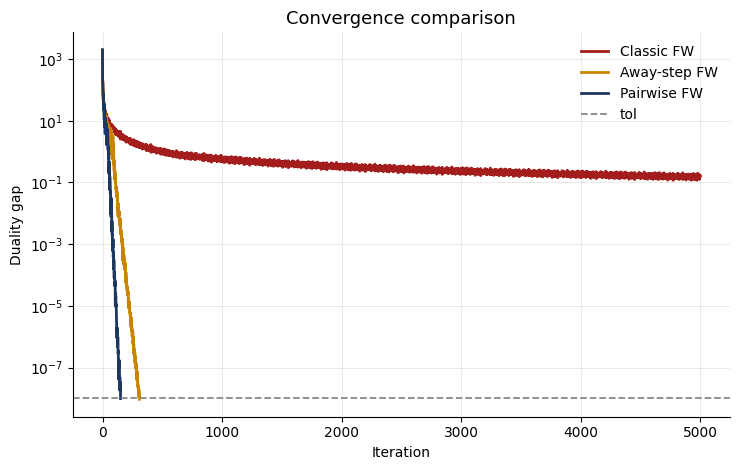

In [ ]:
results = {
    "Classic FW": res_classic,
    "Away-step FW": res_away,
    "Pairwise FW": res_pairwise,
}

plot_gap_comparison(results, tol=1e-8)

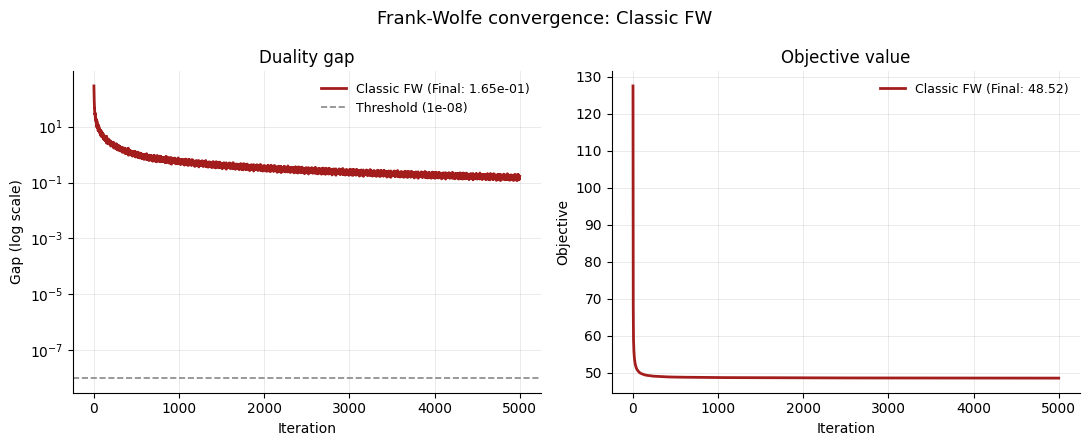

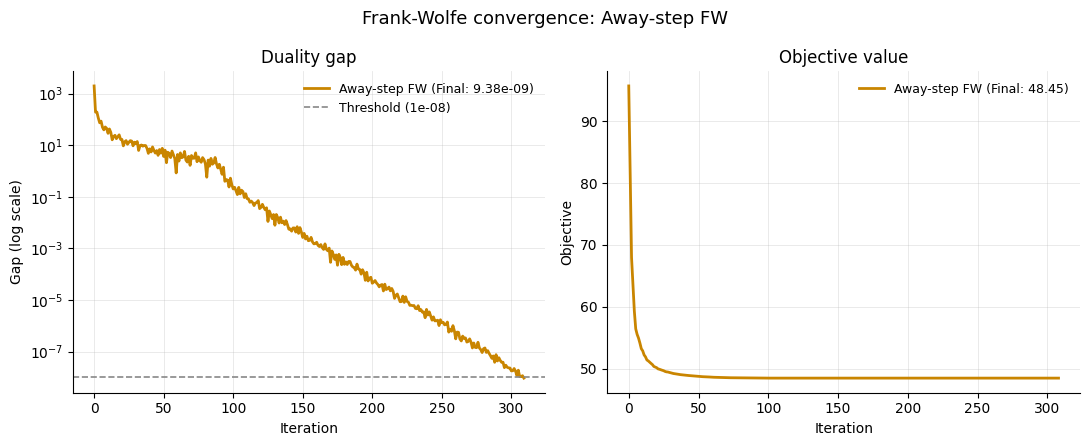

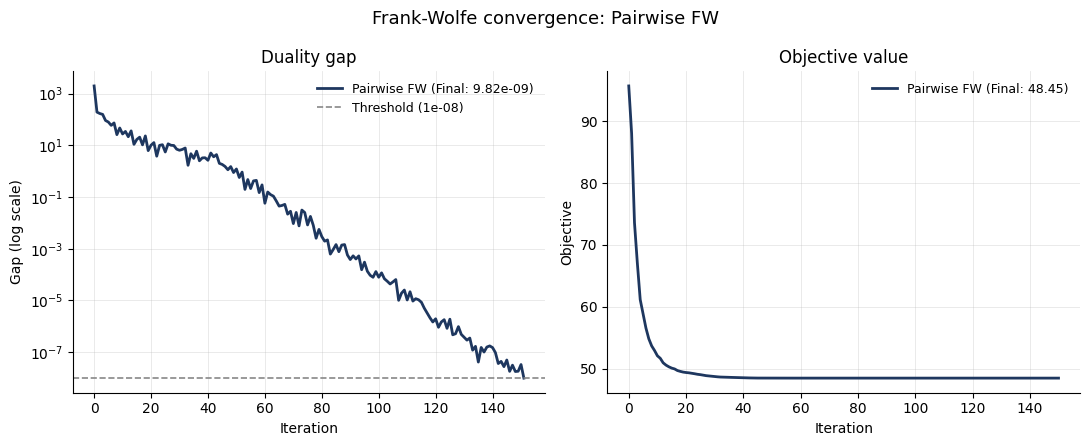

In [ ]:
plot_fw_convergence(res_classic["history"], "Classic FW", color="#a31d1d", tol=1e-8)
plot_fw_convergence(res_away["history"], "Away-step FW", color="#c98500", tol=1e-8)
plot_fw_convergence(res_pairwise["history"], "Pairwise FW", color="#1e375f", tol=1e-8)

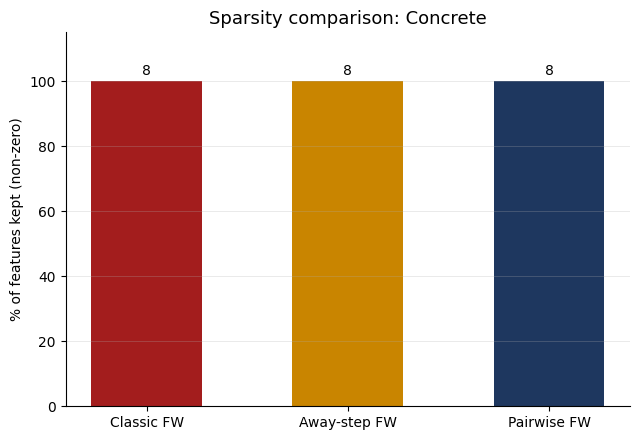

In [ ]:
plot_sparsity_comparison(results, n_features=X_train.shape[1], title="Sparsity comparison: Concrete")

# Dataset 2 : California housing

## Load data

In [ ]:
# Load dataset
data = fetch_california_housing()

X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (20640, 8)
y shape: (20640,)


In [ ]:
# missing values
print("NaNs in X:", np.isnan(X).sum())
print("NaNs in y:", np.isnan(y).sum())

#duplicate rows
df_check = pd.DataFrame(X)
df_check["y"] = y
n_dupes = df_check.duplicated().sum()
print("Duplicate rows:", n_dupes)

# all numeric
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)


NaNs in X: 0
NaNs in y: 0
Duplicate rows: 0
X dtype: float64
y dtype: float64


In [ ]:
# split data : 70/15/15

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# center target
y_mean = y_train.mean()
y_train_c = y_train - y_mean

Train: (14448, 8)  Val: (3096, 8)  Test: (3096, 8)


##choosing t

t_max: 3.4243640561784554


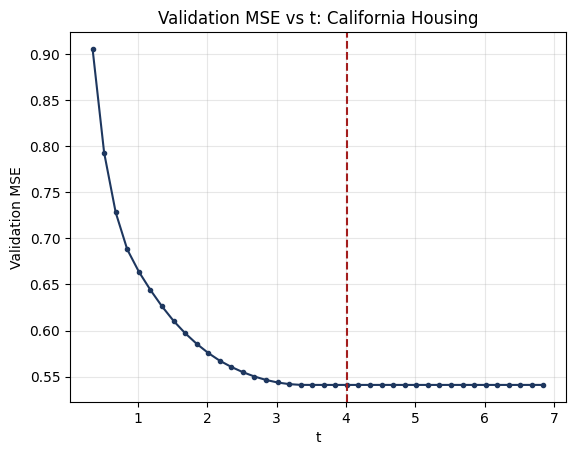

Best t = 4.012652240188601
Best validation MSE = 0.540870620672995
Candidates hitting max_iter cap: 0


In [ ]:
t_best, results_arr = search_t(X_train, y_train_c, X_val, y_val, y_mean,
                                title="Validation MSE vs t: California Housing")

In [ ]:
print("Max iterations used across all candidates:", results_arr["n_iter"].max())
print("Number of candidates that hit the cap:", (results_arr["n_iter"] >= 1000).sum())

Max iterations used across all candidates: 423
Number of candidates that hit the cap: 0


##experiments

In [ ]:
# final eval on test, using t_best
max_iter = 5000

res_classic = evaluate(
    frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_away = evaluate(
    away_step_frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_pairwise = evaluate(
    frank_wolfe_pairwise, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

print(f"{'Method':<15} {'MSE':>10} {'R²':>10} {'Adj R²':>10} {'NNZ':>6} {'Iters':>8} {'Time(s)':>10}")
for name, res in [("Classic FW", res_classic), ("Away-step FW", res_away), ("Pairwise FW", res_pairwise)]:
    print(f"{name:<15} {res['mse']:>10.4f} {res['r2']:>10.4f} {res['adj_r2']:>10.4f} {res['nnz']:>6} {res['n_iter']:>8} {res['time_s']:>10.4f}")

Method                 MSE         R²     Adj R²    NNZ    Iters    Time(s)
Classic FW          0.5201     0.6066     0.6056      8     5000     1.3141
Away-step FW        0.5203     0.6066     0.6055      8     1267     0.3758
Pairwise FW         0.5203     0.6066     0.6055      8      829     0.2305


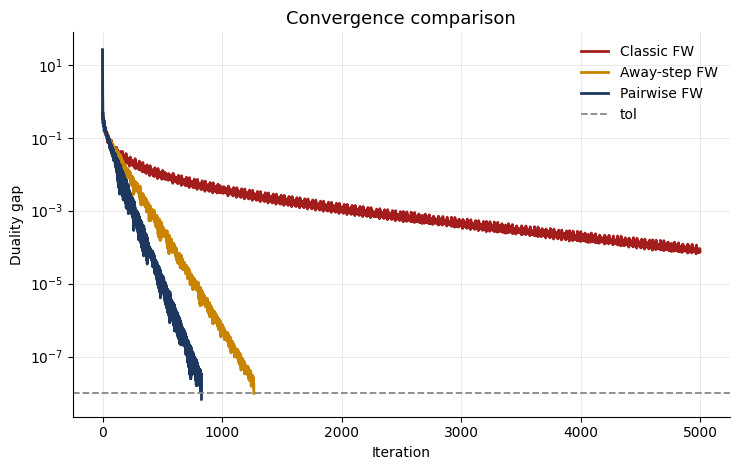

In [ ]:
results = {
    "Classic FW": res_classic,
    "Away-step FW": res_away,
    "Pairwise FW": res_pairwise,
}

plot_gap_comparison(results, tol=1e-8)

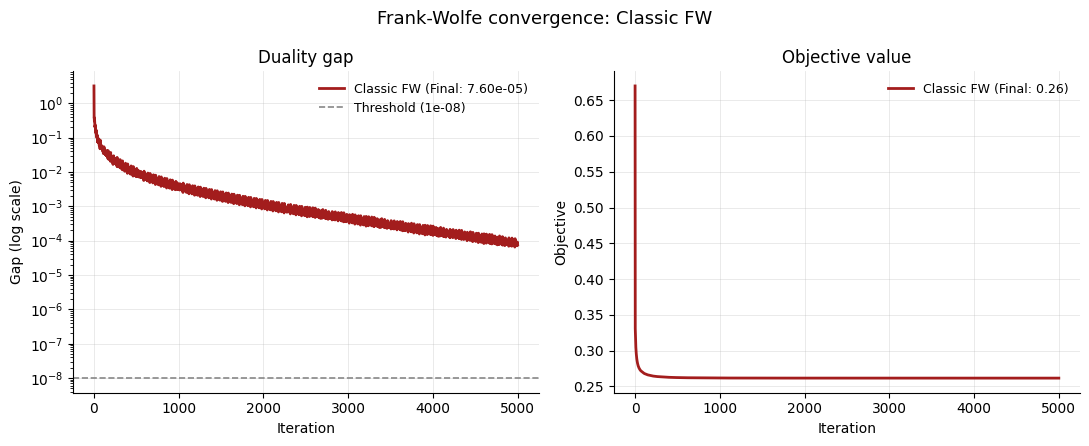

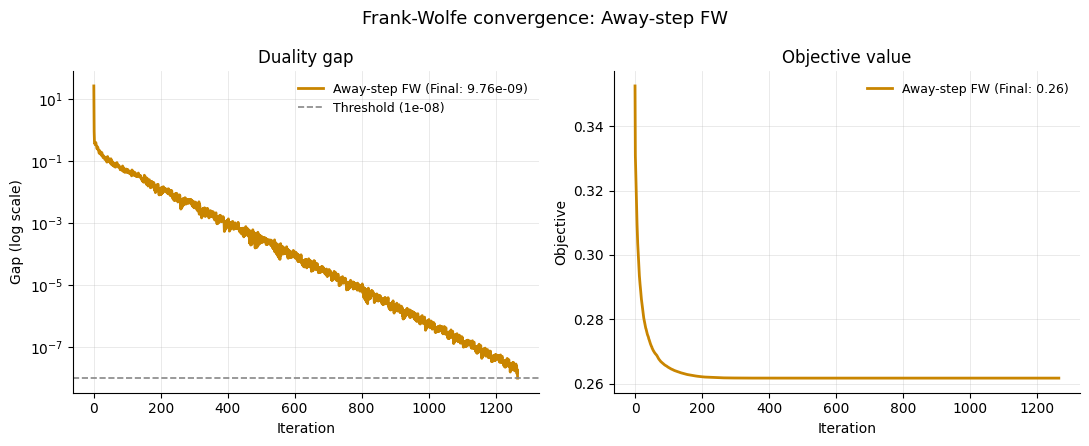

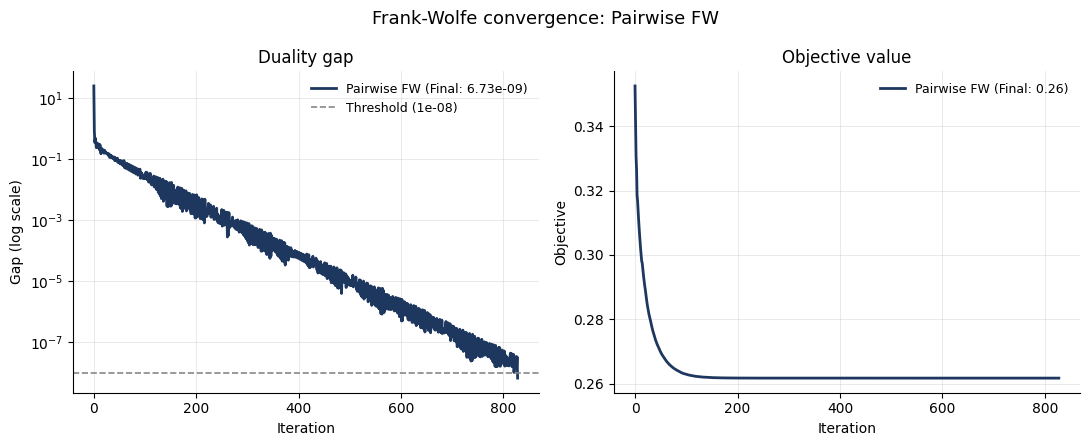

In [ ]:
plot_fw_convergence(res_classic["history"], "Classic FW", color="#a31d1d", tol=1e-8)
plot_fw_convergence(res_away["history"], "Away-step FW", color="#c98500", tol=1e-8)
plot_fw_convergence(res_pairwise["history"], "Pairwise FW", color="#1e375f", tol=1e-8)

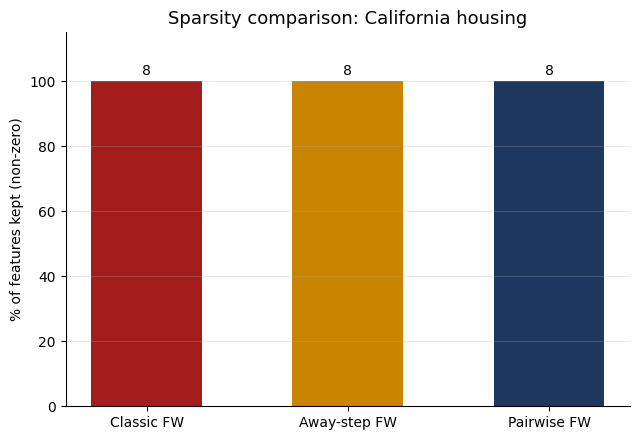

In [ ]:
plot_sparsity_comparison(results, n_features=X_train.shape[1], title="Sparsity comparison: California housing")

# Dataset 3: slice_localization_data


In [ ]:
!wget -O ct.zip "https://archive.ics.uci.edu/static/public/206/relative+location+of+ct+slices+on+axial+axis.zip"
!unzip -o ct.zip


--2026-08-28 11:45:29--  https://archive.ics.uci.edu/static/public/206/relative+location+of+ct+slices+on+axial+axis.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘ct.zip’

ct.zip                  [    <=>             ]  17.00M  22.6MB/s    in 0.8s    

2026-08-28 11:45:30 (22.6 MB/s) - ‘ct.zip’ saved [17823884]

Archive:  ct.zip
  inflating: slice_localization_data.csv  


In [ ]:
df = pd.read_csv("slice_localization_data.csv")
X = df.drop(columns=["patientId", "reference"]).values
y = df["reference"].values


In [ ]:
# missing values
print("NaNs in X:", np.isnan(X).sum())
print("NaNs in y:", np.isnan(y).sum())

#duplicate rows
df_check = pd.DataFrame(X)
df_check["y"] = y
n_dupes = df_check.duplicated().sum()
print("Duplicate rows:", n_dupes)

# all numeric
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)

NaNs in X: 0
NaNs in y: 0
Duplicate rows: 63
X dtype: float64
y dtype: float64


In [ ]:
# remove duplicate
df_full = pd.DataFrame(X)
df_full["y"] = y
df_full = df_full.drop_duplicates()

X = df_full.drop(columns="y").values
y = df_full["y"].values

print(X.shape, y.shape)

(53437, 384) (53437,)


In [ ]:
# train/test/val
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

# standartize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# center target
y_mean = y_train.mean()
y_train_c = y_train - y_mean

## choosing t

t_max: 156.34809229991868


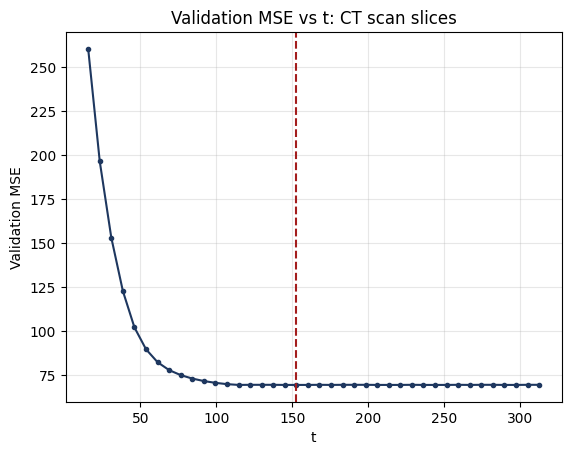

Best t = 152.74005940068977
Best validation MSE = 69.64948077915841
Candidates hitting max_iter cap: 35


In [ ]:
t_best, results_arr = search_t(X_train, y_train_c, X_val, y_val, y_mean,
                                title="Validation MSE vs t: CT scan slices")

## experiments





In [ ]:
# final eval on test, using t_best
max_iter = 5000

res_classic = evaluate(
    frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_away = evaluate(
    away_step_frank_wolfe_lasso, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

res_pairwise = evaluate(
    frank_wolfe_pairwise, max_iter,
    X_train=X_train, y_train_c=y_train_c,
    X_test=X_test, y_test=y_test,
    y_mean=y_mean, t=t_best, tol=1e-8)

print(f"{'Method':<15} {'MSE':>10} {'R²':>10} {'Adj R²':>10} {'NNZ':>6} {'Iters':>8} {'Time(s)':>10}")
for name, res in [("Classic FW", res_classic), ("Away-step FW", res_away), ("Pairwise FW", res_pairwise)]:
    print(f"{name:<15} {res['mse']:>10.4f} {res['r2']:>10.4f} {res['adj_r2']:>10.4f} {res['nnz']:>6} {res['n_iter']:>8} {res['time_s']:>10.4f}")

Method                 MSE         R²     Adj R²    NNZ    Iters    Time(s)
Classic FW         69.1634     0.8625     0.8571    303     5000   111.4859
Away-step FW       68.8388     0.8632     0.8571    340     5000   114.9801
Pairwise FW        68.8327     0.8632     0.8570    347     5000   113.4284


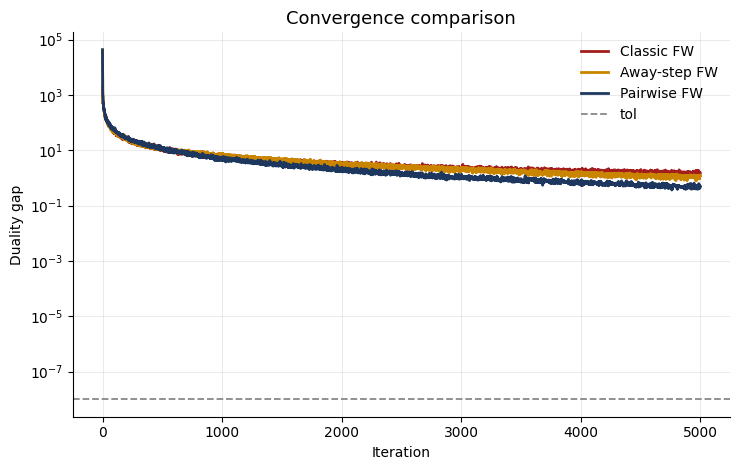

In [ ]:
results = {
    "Classic FW": res_classic,
    "Away-step FW": res_away,
    "Pairwise FW": res_pairwise,
}
plot_gap_comparison(results, tol=1e-8)

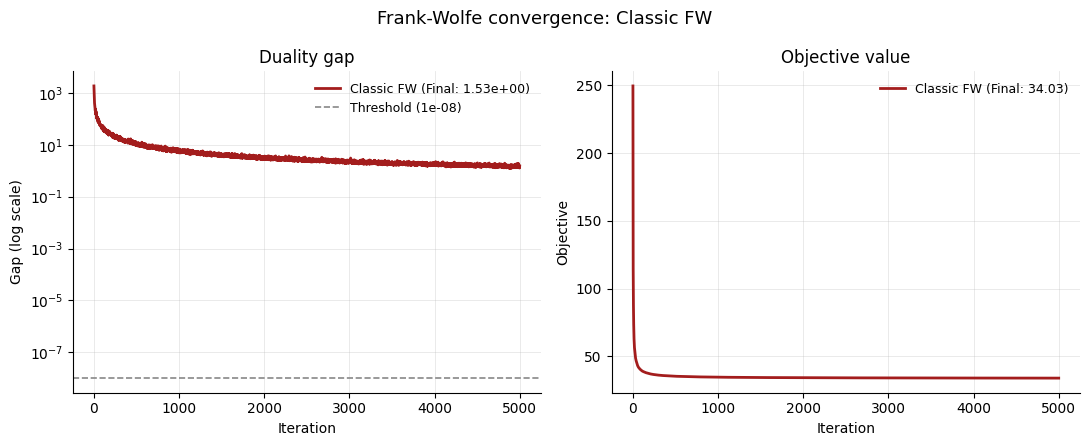

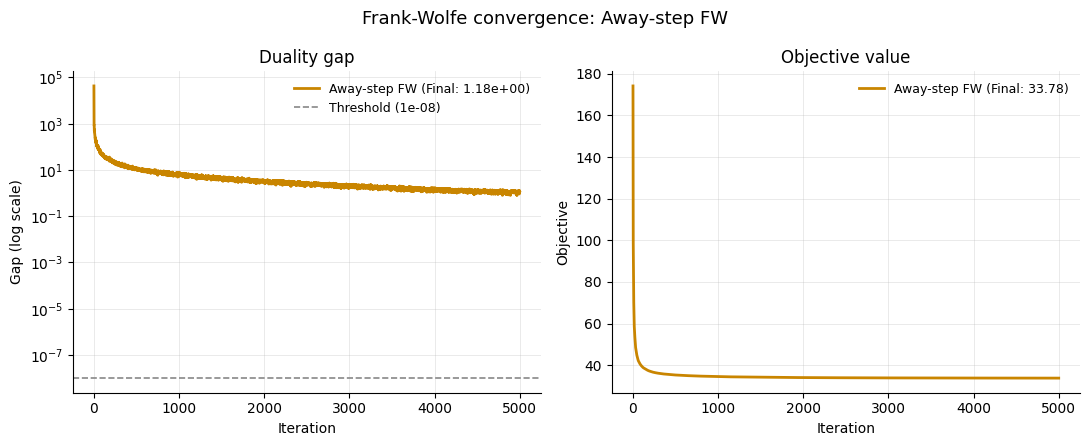

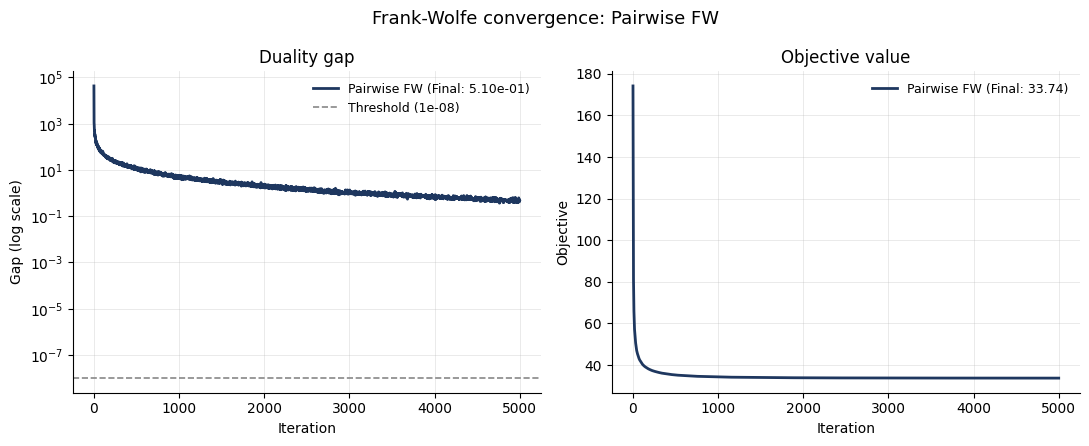

In [ ]:
plot_fw_convergence(res_classic["history"], "Classic FW", color="#a31d1d", tol=1e-8)
plot_fw_convergence(res_away["history"], "Away-step FW", color="#c98500", tol=1e-8)
plot_fw_convergence(res_pairwise["history"], "Pairwise FW", color="#1e375f", tol=1e-8)

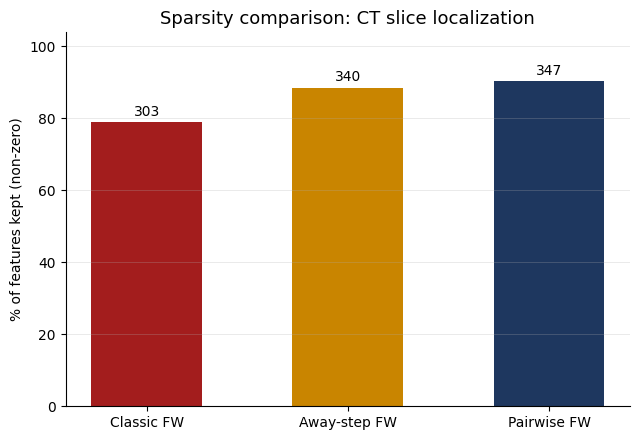

In [ ]:
plot_sparsity_comparison(results, n_features=X_train.shape[1], title="Sparsity comparison: CT slice localization")

# Dataset 4 : Dorothea (classification task)

In [ ]:
!wget -O dorothea.zip "https://archive.ics.uci.edu/static/public/169/dorothea.zip"
!unzip -o dorothea.zip -d dorothea_raw

def load_dorothea_data(path, n_features=100000):
    with open(path) as f:
        lines = f.readlines()
    rows = []
    for line in lines:
        indices = [int(i) - 1 for i in line.split()]
        row = np.zeros(n_features, dtype=np.uint8)
        row[indices] = 1
        rows.append(row)
    return np.array(rows, dtype=np.uint8)

def load_dorothea_labels(path):
    with open(path) as f:
        return np.array([int(x) for x in f.read().split()])

X_train_raw = load_dorothea_data("dorothea_raw/DOROTHEA/dorothea_train.data")
y_train_raw = load_dorothea_labels("dorothea_raw/DOROTHEA/dorothea_train.labels")

X_valid_raw = load_dorothea_data("dorothea_raw/DOROTHEA/dorothea_valid.data")
y_valid_raw = load_dorothea_labels("dorothea_raw/dorothea_valid.labels")

# combine train + valid (test labels are withheld, unusable)
X = np.vstack([X_train_raw, X_valid_raw])
y_raw = np.concatenate([y_train_raw, y_valid_raw])

print(X.shape, y_raw.shape)
print(np.unique(y_raw))

y = (y_raw == 1).astype(int)  # remap to 0/1
print("class balance:", np.bincount(y))

--2026-08-28 12:12:58--  https://archive.ics.uci.edu/static/public/169/dorothea.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘dorothea.zip’

dorothea.zip            [   <=>              ]   4.82M  9.44MB/s    in 0.5s    

2026-08-28 12:12:59 (9.44 MB/s) - ‘dorothea.zip’ saved [5055101]

Archive:  dorothea.zip
  inflating: dorothea_raw/DOROTHEA/dorothea.param  
  inflating: dorothea_raw/DOROTHEA/dorothea_test.data  
  inflating: dorothea_raw/DOROTHEA/dorothea_train.data  
  inflating: dorothea_raw/DOROTHEA/dorothea_train.labels  
  inflating: dorothea_raw/DOROTHEA/dorothea_valid.data  
  inflating: dorothea_raw/Dataset.pdf  
  inflating: dorothea_raw/dorothea_valid.labels  
(1150, 100000) (1150,)
[-1  1]
class balance: [1038  112]


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(X_train.shape, X_val.shape, X_test.shape)

(805, 100000) (172, 100000) (173, 100000)


# Selecting t


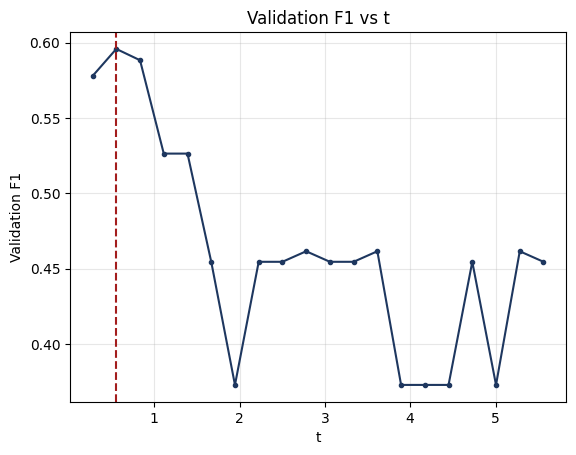

Best t = 0.5562263977824476  Best val F1 = 0.5957446808510638
Candidates hitting cap: 3


In [ ]:
ols = LinearRegression(fit_intercept=False).fit(X_train, y_train)
t_max = np.linalg.norm(ols.coef_, 1)

ts = np.linspace(0.05, 1.0, 20) * t_max
results = []

for t_cand in ts:
    beta, hist = frank_wolfe_pairwise(X_train, y_train, t=t_cand, max_iter=1000, tol=1e-4)
    probs_val = 1 / (1 + np.exp(-X_val.dot(beta)))
    y_pred_val = (probs_val >= 0.5).astype(int)
    f1 = f1_score(y_val, y_pred_val)
    results.append((t_cand, f1, len(hist["duality_gap"])))

results_arr = np.array(results, dtype=[('t', float), ('f1', float), ('n_iter', int)])
best = results_arr[np.argmax(results_arr['f1'])]
t_best = best["t"]

plt.plot(results_arr["t"], results_arr["f1"], "-o", markersize=3, color="#1e375f")
plt.axvline(t_best, color="#a31d1d", linestyle="--")
plt.xlabel("t")
plt.ylabel("Validation F1")
plt.title("Validation F1 vs t")
plt.grid(True, alpha=0.3)
plt.show()

print("Best t =", t_best, " Best val F1 =", best["f1"])
print("Candidates hitting cap:", (results_arr["n_iter"] >= 1000).sum())

In [ ]:
best_idx = np.argmax(results_arr['f1'])
print("t_best's n_iter:", results_arr['n_iter'][best_idx])
print("Did t_best hit the cap?", results_arr['n_iter'][best_idx] >= 1000)

t_best's n_iter: 272
Did t_best hit the cap? False


#Experiment

In [ ]:
def evaluate_classification(method_fn, max_iter, X_train, y_train, X_test, y_test, t, tol=1e-8):
    start = time.perf_counter()
    beta, history = method_fn(X_train, y_train, t, max_iter=max_iter, tol=tol)
    elapsed = time.perf_counter() - start

    probs = 1 / (1 + np.exp(-X_test.dot(beta)))
    y_pred = (probs >= 0.5).astype(int)

    return {
        "time_s": elapsed,
        "acc": accuracy_score(y_test, y_pred),
        "prec": precision_score(y_test, y_pred),
        "rec": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, probs),
        "cm": confusion_matrix(y_test, y_pred),
        "nnz": np.count_nonzero(np.abs(beta) > 1e-10),
        "n_iter": len(history["duality_gap"]),
        "history": history,
        "beta": beta,
    }

In [ ]:
max_iter = 5000

res_classic = evaluate_classification(frank_wolfe_lasso, max_iter, X_train, y_train, X_test, y_test, t=t_best)
res_away = evaluate_classification(away_step_frank_wolfe_lasso, max_iter, X_train, y_train, X_test, y_test, t=t_best)
res_pairwise = evaluate_classification(frank_wolfe_pairwise, max_iter, X_train, y_train, X_test, y_test, t=t_best)

print(f"{'Method':<15} {'Acc':>8} {'Prec':>8} {'Rec':>8} {'F1':>8} {'AUC':>8} {'NNZ':>6} {'Iters':>8} {'Time(s)':>10}")
for name, res in [("Classic FW", res_classic), ("Away-step FW", res_away), ("Pairwise FW", res_pairwise)]:
    print(f"{name:<15} {res['acc']:>8.4f} {res['prec']:>8.4f} {res['rec']:>8.4f} {res['f1']:>8.4f} {res['auc']:>8.4f} {res['nnz']:>6} {res['n_iter']:>8} {res['time_s']:>10.4f}")

for name, res in [("Classic FW", res_classic), ("Away-step FW", res_away), ("Pairwise FW", res_pairwise)]:
    print(f"\n{name} confusion matrix:\n{res['cm']}")

Method               Acc     Prec      Rec       F1      AUC    NNZ    Iters    Time(s)
Classic FW        0.9133   0.5455   0.7059   0.6154   0.8484     63     5000   559.6862
Away-step FW      0.9133   0.5455   0.7059   0.6154   0.8477     58     2684   304.7308
Pairwise FW       0.9133   0.5455   0.7059   0.6154   0.8484     58     1077   121.0527

Classic FW confusion matrix:
[[146  10]
 [  5  12]]

Away-step FW confusion matrix:
[[146  10]
 [  5  12]]

Pairwise FW confusion matrix:
[[146  10]
 [  5  12]]


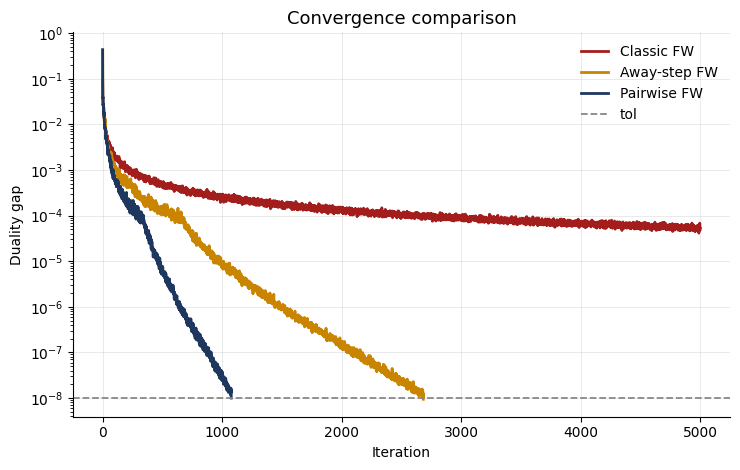

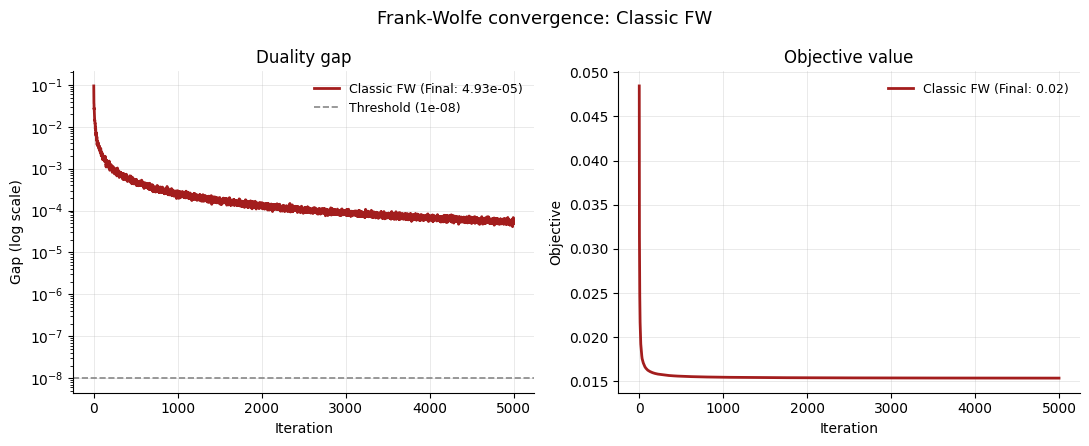

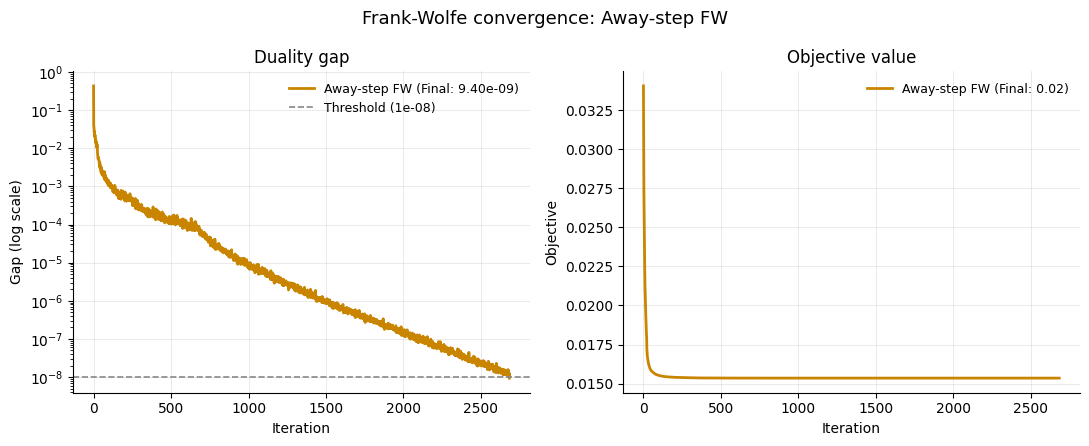

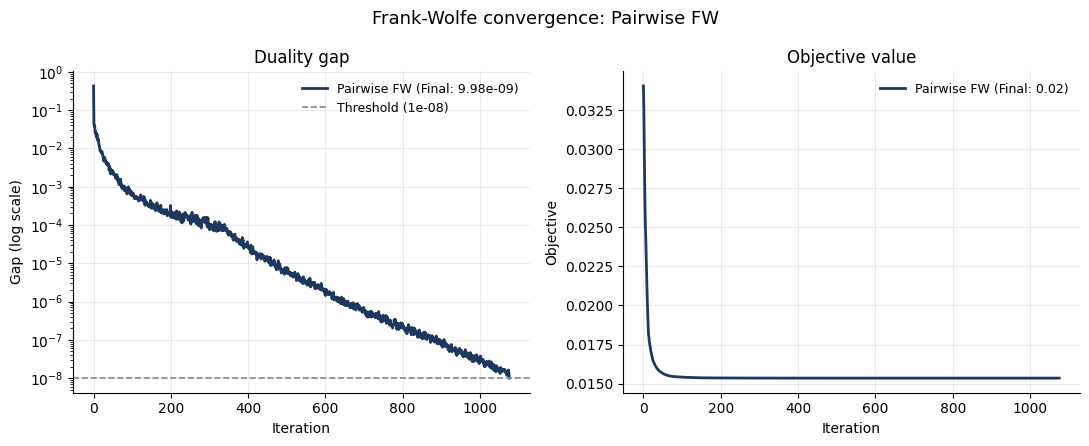

In [ ]:
results = {"Classic FW": res_classic, "Away-step FW": res_away, "Pairwise FW": res_pairwise}
plot_gap_comparison(results, tol=1e-8)

plot_fw_convergence(res_classic["history"], "Classic FW", color="#a31d1d", tol=1e-8)
plot_fw_convergence(res_away["history"], "Away-step FW", color="#c98500", tol=1e-8)
plot_fw_convergence(res_pairwise["history"], "Pairwise FW", color="#1e375f", tol=1e-8)

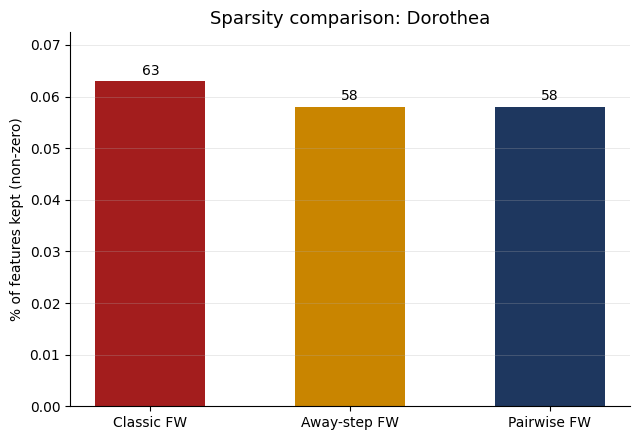

In [ ]:
plot_sparsity_comparison(results, n_features=X_train.shape[1], title="Sparsity comparison: Dorothea")